<table style="border:none;border-collapse:collapse;margin:0 0 8px;width:100%;">
<tr style="border:none;">
  <td style="border:none;padding:0;vertical-align:middle;">
    <div style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.2em;text-transform:uppercase;color:#A20025;margin:0 0 7px;">Companion notebook</div>
    <div style="font-family:Georgia,'Iowan Old Style',serif;font-size:18px;color:#1A1416;line-height:1.25;margin:0 0 7px;">
      <a href="https://www.manning.com/books/build-ai-drug-discovery-pipelines" style="color:#1A1416;text-decoration:none;border-bottom:1px solid #A20025;padding-bottom:1px;">Build AI Drug Discovery Pipelines</a>
    </div>
    <div style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:12px;color:#6B6461;line-height:1.7;">
      Noah Flynn&nbsp;&middot;&nbsp;Manning Publications<br>
      Code&nbsp;&middot;&nbsp;<a href="https://github.com/nrflynn2/ml-drug-discovery" style="color:#A20025;text-decoration:none;">github.com/nrflynn2/ml-drug-discovery</a>
    </div>
  </td>
  <td style="border:none;padding:0 0 0 22px;vertical-align:middle;width:104px;text-align:right;">
    <a href="https://www.manning.com/books/build-ai-drug-discovery-pipelines">
      <img src="https://raw.githubusercontent.com/nrflynn2/ml-drug-discovery/main/assets/cover-sm.png" width="88" alt="Build AI Drug Discovery Pipelines cover" style="border:1px solid #E7E2DF;border-radius:3px;display:inline-block;">
    </a>
  </td>
</tr>
</table>
<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:0 0 22px;">

<div style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.24em;text-transform:uppercase;color:#A20025;margin:0 0 12px;">Chapter 7</div>

<h1 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:33px;line-height:1.12;margin:0 0 16px;color:#1A1416;letter-spacing:-.01em;">Mutation Effect Prediction with ESM-2</h1>

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:0 0 4px;">

<em style="color:#6B6461;font-size:14.5px;">Runnable code for Chapter 7; read alongside the book.</em>

<a href="https://colab.research.google.com/github/nrflynn2/ml-drug-discovery/blob/main/CH07_FLYNN_ML4DD/notebooks/ch07-mutation-scoring.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in-Colab-A20025?logo=googlecolab&logoColor=white" alt="Open in Colab" style="height:20px;vertical-align:middle;"></a>

Predicting how mutations affect protein function is a fundamental challenge in protein engineering,
drug design, and understanding disease. Traditional approaches require expensive experiments for each
variant. But what if we could predict mutation effects computationally, using only sequence information?

**ESM-2**, trained on 65 million protein sequences, has learned deep patterns about which amino acid
combinations are biologically plausible. We can leverage this knowledge to score mutations in a
**zero-shot** manner - without any experimental data for the specific protein!

This notebook demonstrates three complementary approaches:

1. **Mutation Heatmap**: Visualize effects of ALL possible mutations across a sequence
2. **Deep Mutational Scanning (DMS)**: Score specific mutations from a list
3. **Pseudo-Perplexity (PPPL)**: Evaluate overall sequence quality/naturalness

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">Real-World Applications</h2>

- **Protein Engineering**: Identify stabilizing mutations for therapeutic antibodies
- **Disease Genetics**: Predict pathogenicity of genetic variants
- **Directed Evolution**: Prioritize mutations for experimental screening
- **Antibody Optimization**: Improve binding affinity, reduce immunogenicity
- **Quality Control**: Evaluate designed sequences before synthesis

<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Objectives</strong>
<ol style="margin:8px 0 0;padding-left:22px;font-size:15.5px;color:#241c1d;">
<li style="margin:6px 0;">Understand log-likelihood ratios for mutation scoring</li>
<li style="margin:6px 0;">Create comprehensive mutation heatmaps</li>
<li style="margin:6px 0;">Implement three scoring strategies: wild-type, masked, and pseudo-perplexity</li>
<li style="margin:6px 0;">Choose ESM-2 model sizes for different tasks</li>
<li style="margin:6px 0;">Interpret mutation scores in biological context</li>
<li style="margin:6px 0;">Apply these methods to protein-engineering problems</li>
</ol>

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§0&#8195;</span>Setup and Installation</h2>

<div style="font-size:14px;margin:0 0 6px;">
<div style="display:flex;gap:14px;padding:9px 0;border-bottom:1px solid #EFEBE8;"><strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.06em;text-transform:uppercase;color:#A20025;min-width:96px;">Local&#8195;&#8195;</strong><span>The Chapter 7 code is a self-contained package. From <code>CH07_FLYNN_ML4DD/</code>, run <code>pip install -e ".[notebooks]"</code> (Python 3.12).</span></div>
<div style="display:flex;gap:14px;padding:9px 0;"><strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.06em;text-transform:uppercase;color:#A20025;min-width:96px;">Colab&#8195;&#8195;</strong><span>Clone the repository, then <code>pip install -e "ml-drug-discovery/CH07_FLYNN_ML4DD[notebooks]"</code>; a GPU runtime is recommended.</span></div>
</div>

First, let's install all required packages and set up our environment.

In [ ]:
# Colab users only: install the required packages, then continue below.
# Skipped on a local run -- the chapter environment already provides these, and
# re-running pip would churn the local install.
!pip install -q transformers torch matplotlib numpy pandas biopython tqdm ipywidgets cmocean

In [1]:
# Standard library imports
import os
import sys
import string
import random
import itertools
from pathlib import Path
from collections import defaultdict

# Core scientific computing
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Visualization
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Progress bars
from tqdm.auto import tqdm

# Hugging Face Transformers
import transformers
from transformers import AutoTokenizer, EsmForMaskedLM, AutoModelForMaskedLM

# BioPython for sequence handling
from Bio import SeqIO
from Bio.Seq import Seq

# Jupyter widgets for interactive features
import ipywidgets as widgets
from IPython.display import display, HTML

# Set random seeds for reproducibility (Python, NumPy and PyTorch all draw here)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Report the environment, so this notebook's outputs are self-documenting
print(f"Python      : {sys.version.split()[0]}")
for _m in (np, pd, torch, transformers, matplotlib):
    print(f"{_m.__name__:12s}: {_m.__version__}")

# Pick the best available device. `torch.accelerator` covers CUDA, Apple MPS and
# XPU with one API, so this notebook is not CUDA-only (it matches the
# `get_device()` helper in src/utils.py that the rest of Chapter 7 uses).
device = torch.device(
    torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"
)
print(f"\nDevice: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

# Configure plotting
plt.style.use('default')
sns.set_palette("husl")

Python      : 3.12.13
numpy       : 2.2.6
pandas      : 2.3.3
torch       : 2.12.1+cu130
transformers: 5.14.1
matplotlib  : 3.11.0

Device: cpu


<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">Understanding Mutation Scoring with Log-Likelihood Ratios</h2>

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">The Core Idea</h3>

ESM-2 learns to predict masked amino acids. We can use these predictions to score mutations:

**Log-Likelihood Ratio (LLR)** = log P(mutant | context) - log P(wild-type | context)

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Interpretation</h3>

- **Negative LLR** (< 0): Mutation decreases sequence likelihood to Likely **deleterious**
- **LLR ≈ 0**: Mutation neutral to **Tolerated**
- **Positive LLR** (> 0): Mutation increases likelihood to Potentially **beneficial**

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Intuition</h3>

Think of ESM-2 as having "read" 65 million proteins. It knows which amino acid patterns are
common (evolutionary conserved) and which are rare (likely harmful). The LLR quantifies this.

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Simple Example</h3>

Original: `MKTAY`**K**`AKQR` (position 6 = K)
Mutation: `MKTAY`**R**`AKQR` (K6R)

1. Mask position 6: `MKTAY[MASK]AKQR`
2. ESM-2 predicts: P(K) = 0.45, P(R) = 0.35
3. LLR = log(0.35) - log(0.45) = -0.25
4. Interpretation: K6R slightly deleterious (negative LLR)

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§1&#8195;</span>Load ESM-2 Model</h2>

ESM-2 comes in multiple sizes. Choose based on your needs:

| Model | Parameters | Layers | Speed | Accuracy | GPU Memory | Use Case |
|-------|-----------|--------|-------|----------|------------|----------|
| t6_8M | 8M | 6 | Fastest | Good | ~1 GB | Quick prototyping |
| t12_35M | 35M | 12 | Fast | Better | ~2 GB | **Recommended for Colab** |
| t30_150M | 150M | 30 | Medium | Great | ~4 GB | Production (small GPU) |
| t33_650M | 650M | 33 | Slow | Excellent | ~8 GB | Production (large GPU) |
| t36_3B | 3B | 36 | Very slow | Best | ~16 GB | Research |

We'll use **t12_35M** for good balance of speed and accuracy on Colab.

In [2]:
# Load model and tokenizer
model_name = "facebook/esm2_t12_35M_UR50D"  # 35M parameter model (fast, accurate)

print(f"Loading {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmForMaskedLM.from_pretrained(model_name)

# Move to GPU
model = model.to(device)
model.eval()

print(f"\nModel loaded successfully!")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Layers: {model.config.num_hidden_layers}")
print(f"  Embedding dim: {model.config.hidden_size}")
print(f"  Vocabulary size: {model.config.vocab_size}")

# Get mask token ID
mask_token_id = tokenizer.mask_token_id
print(f"  Mask token ID: {mask_token_id}")

Loading facebook/esm2_t12_35M_UR50D...


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]


Model loaded successfully!
  Parameters: 33,501,394
  Layers: 12
  Embedding dim: 480
  Vocabulary size: 33
  Mask token ID: 32


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§2&#8195;</span>Example Protein Sequence</h2>

Let's work with a real antibody complementarity-determining region (CDR) sequence.
This is where antibodies bind to antigens, so mutations here significantly affect function.

In [3]:
# Example: Antibody CDR-H3 region (highly variable, critical for binding)
wild_type_sequence = "EVQLVESGGGLVQPGGSLRLSCAASGFTFSSYAMSWVRQAPGKGLEWVSAISGSGGSTYYADSVKG"

print(f"Wild-type sequence:")
print(f"  Length: {len(wild_type_sequence)} amino acids")
print(f"  Sequence: {wild_type_sequence}")
print(f"\nThis is an antibody heavy chain variable region.")
print(f"Mutations in this region can affect:")
print(f"  - Antigen binding specificity")
print(f"  - Binding affinity")
print(f"  - Protein stability")
print(f"  - Immunogenicity")

Wild-type sequence:
  Length: 66 amino acids
  Sequence: EVQLVESGGGLVQPGGSLRLSCAASGFTFSSYAMSWVRQAPGKGLEWVSAISGSGGSTYYADSVKG

This is an antibody heavy chain variable region.
Mutations in this region can affect:
  - Antigen binding specificity
  - Binding affinity
  - Protein stability
  - Immunogenicity


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§3&#8195;</span>Approach 1 - Comprehensive Mutation Heatmap</h2>

Let's create a **mutation landscape** showing the predicted effect of EVERY possible single
amino acid substitution. This gives us a complete picture of which positions are conserved
and which tolerate mutations.

In [4]:
def compute_mutation_scores(sequence, model, tokenizer, device):
    """
    Compute log-likelihood ratios for all possible single mutations.

    Args:
        sequence: Wild-type protein sequence (string)
        model: ESM model for masked language modeling
        tokenizer: ESM tokenizer
        device: torch device

    Returns:
        scores: (20, len(sequence)) array of LLRs
        amino_acids: List of 20 standard amino acids
    """
    # Standard amino acids
    amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

    # Initialize score matrix
    n_positions = len(sequence)
    n_amino_acids = len(amino_acids)
    scores = np.zeros((n_amino_acids, n_positions))

    model.eval()

    # Process each position
    for pos in tqdm(range(n_positions), desc="Computing scores"):
        # Create masked sequence
        masked_seq = sequence[:pos] + tokenizer.mask_token + sequence[pos+1:]

        # Tokenize
        tokens = tokenizer(masked_seq, return_tensors="pt")
        tokens = {k: v.to(device) for k, v in tokens.items()}

        # Get predictions
        with torch.no_grad():
            outputs = model(**tokens)
            logits = outputs.logits

        # Find the masked position in tokens (accounting for <cls> token at position 0)
        mask_token_index = (tokens['input_ids'] == tokenizer.mask_token_id).nonzero(as_tuple=True)[1]

        # Get log probabilities at masked position
        log_probs = F.log_softmax(logits[0, mask_token_index[0]], dim=0)

        # Get wild-type amino acid
        wt_amino_acid = sequence[pos]
        wt_token_id = tokenizer.convert_tokens_to_ids(wt_amino_acid)
        wt_log_prob = log_probs[wt_token_id].item()

        # Compute LLR for each possible mutation
        for i, mutant_aa in enumerate(amino_acids):
            mutant_token_id = tokenizer.convert_tokens_to_ids(mutant_aa)
            mutant_log_prob = log_probs[mutant_token_id].item()

            # LLR = log P(mutant) - log P(wt)
            llr = mutant_log_prob - wt_log_prob
            scores[i, pos] = llr

    return scores, amino_acids

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Compute Scores for Our Example Sequence</h3>

This will take a few minutes depending on sequence length and GPU.

In [5]:
print("Computing mutation scores for all positions...")
print(f"This will evaluate {len(wild_type_sequence)} positions × 20 amino acids = {len(wild_type_sequence) * 20} mutations")

mutation_scores, amino_acids = compute_mutation_scores(
    wild_type_sequence,
    model,
    tokenizer,
    device
)

print(f"\nDone! Score matrix shape: {mutation_scores.shape}")
print(f"  Rows: {len(amino_acids)} amino acids")
print(f"  Columns: {len(wild_type_sequence)} positions")

# Sanity checks: one column per residue, one row per amino acid, and the
# wild-type-vs-wild-type LLR must be exactly 0 by construction (log p - log p).
assert mutation_scores.shape == (20, len(wild_type_sequence))
assert np.isfinite(mutation_scores).all(), "non-finite LLRs in the score matrix"
_wt_llrs = [mutation_scores[amino_acids.index(aa), i]
            for i, aa in enumerate(wild_type_sequence)]
assert np.allclose(_wt_llrs, 0.0), "LLR of the wild-type residue against itself should be 0"
print("  ✓ wild-type self-LLRs are all 0, as expected")

Computing mutation scores for all positions...
This will evaluate 66 positions × 20 amino acids = 1320 mutations


Computing scores:   0%|          | 0/66 [00:00<?, ?it/s]


Done! Score matrix shape: (20, 66)
  Rows: 20 amino acids
  Columns: 66 positions
  ✓ wild-type self-LLRs are all 0, as expected


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Visualize the Mutation Heatmap</h3>

Now let's create a beautiful heatmap showing the mutation landscape.

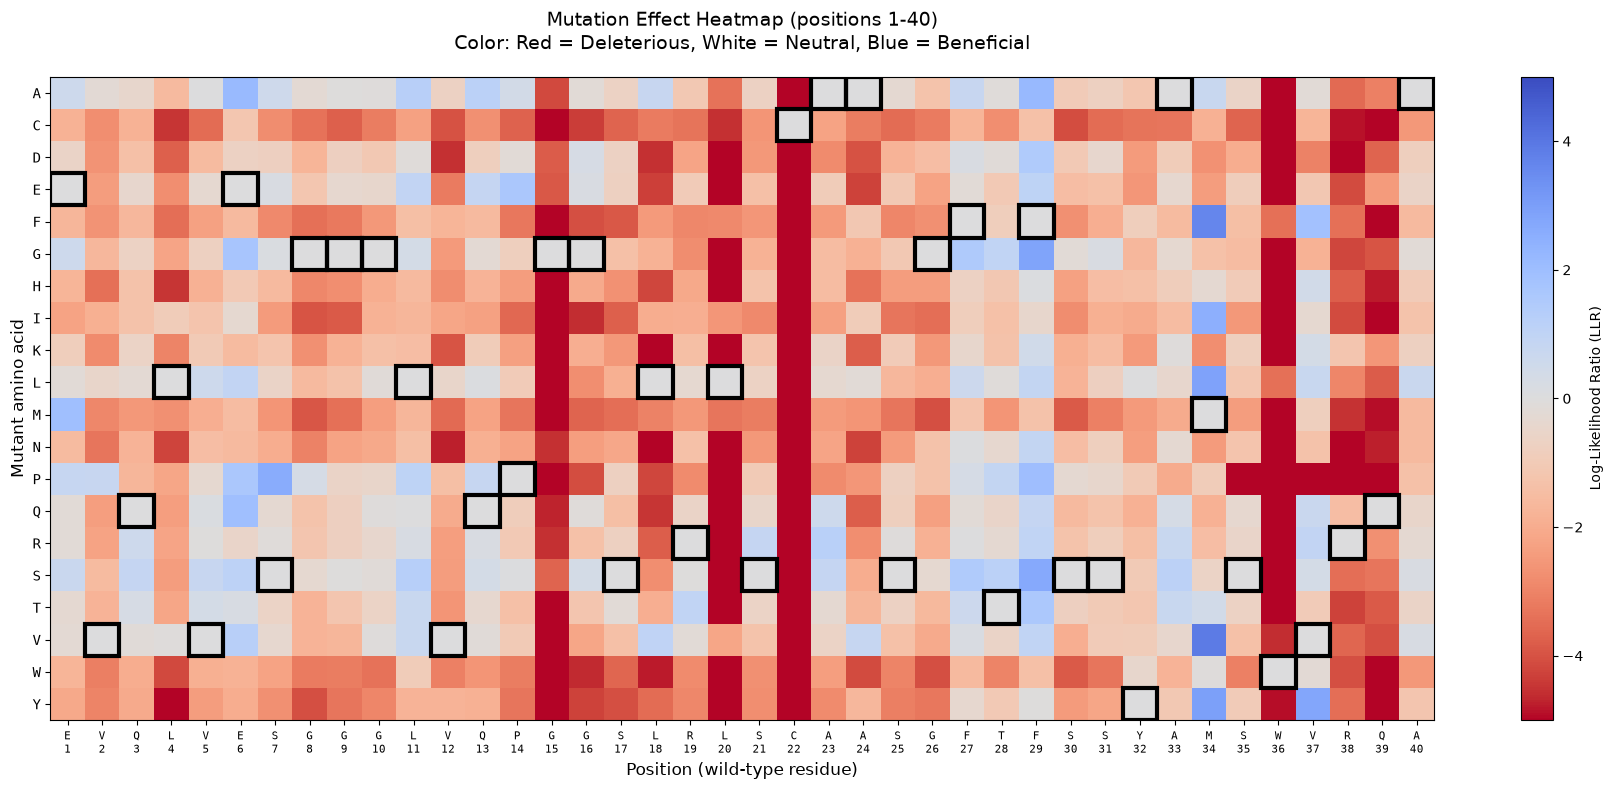


Interpretation:
  - Black boxes: Wild-type amino acid at each position
  - Dark red: Highly deleterious mutations (LLR < -2)
  - White: Neutral mutations (LLR ≈ 0)
  - Dark Blue: Potentially beneficial mutations (LLR > 0)
  - Vertical dark red columns: Highly conserved positions


In [6]:
def plot_mutation_heatmap(scores, amino_acids, sequence, start_pos=0, end_pos=None, figsize=(16, 8)):
    """
    Plot mutation heatmap with interactive region selection.

    Args:
        scores: (n_amino_acids, n_positions) LLR matrix
        amino_acids: List of amino acid letters
        sequence: Wild-type sequence
        start_pos: Start position to display (0-indexed)
        end_pos: End position to display (None = all)
        figsize: Figure size
    """
    if end_pos is None:
        end_pos = len(sequence)

    # Subset scores
    scores_subset = scores[:, start_pos:end_pos]
    seq_subset = sequence[start_pos:end_pos]

    # Create figure
    fig, ax = plt.subplots(figsize=figsize)

    # Plot heatmap
    im = ax.imshow(scores_subset, aspect='auto', cmap="coolwarm_r", vmin=-5, vmax=5)

    # Set ticks
    ax.set_xticks(range(len(seq_subset)))
    ax.set_xticklabels([f"{seq_subset[i]}\n{start_pos+i+1}" for i in range(len(seq_subset))],
                        fontsize=8, family='monospace')
    ax.set_yticks(range(len(amino_acids)))
    ax.set_yticklabels(amino_acids, fontsize=10, family='monospace')

    ax.set_xlabel("Position (wild-type residue)", fontsize=12)
    ax.set_ylabel("Mutant amino acid", fontsize=12)
    ax.set_title(f"Mutation Effect Heatmap (positions {start_pos+1}-{end_pos})\n" +
                 "Color: Red = Deleterious, White = Neutral, Blue = Beneficial",
                 fontsize=14, pad=20)

    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, label="Log-Likelihood Ratio (LLR)")
    cbar.ax.tick_params(labelsize=10)

    # Highlight wild-type residues
    for pos_idx in range(len(seq_subset)):
        wt_aa = seq_subset[pos_idx]
        aa_idx = amino_acids.index(wt_aa)
        rect = plt.Rectangle((pos_idx - 0.5, aa_idx - 0.5), 1, 1,
                             fill=False, edgecolor='black', linewidth=3)
        ax.add_patch(rect)

    plt.tight_layout()
    plt.show()

# Plot full heatmap (may be wide for long sequences)
plot_mutation_heatmap(mutation_scores, amino_acids, wild_type_sequence,
                      start_pos=0, end_pos=40, figsize=(18, 8))

print("\nInterpretation:")
print("  - Black boxes: Wild-type amino acid at each position")
print("  - Dark red: Highly deleterious mutations (LLR < -2)")
print("  - White: Neutral mutations (LLR ≈ 0)")
print("  - Dark Blue: Potentially beneficial mutations (LLR > 0)")
print("  - Vertical dark red columns: Highly conserved positions")

/tmp/ipykernel_17600/3312097141.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels, fontsize=9)


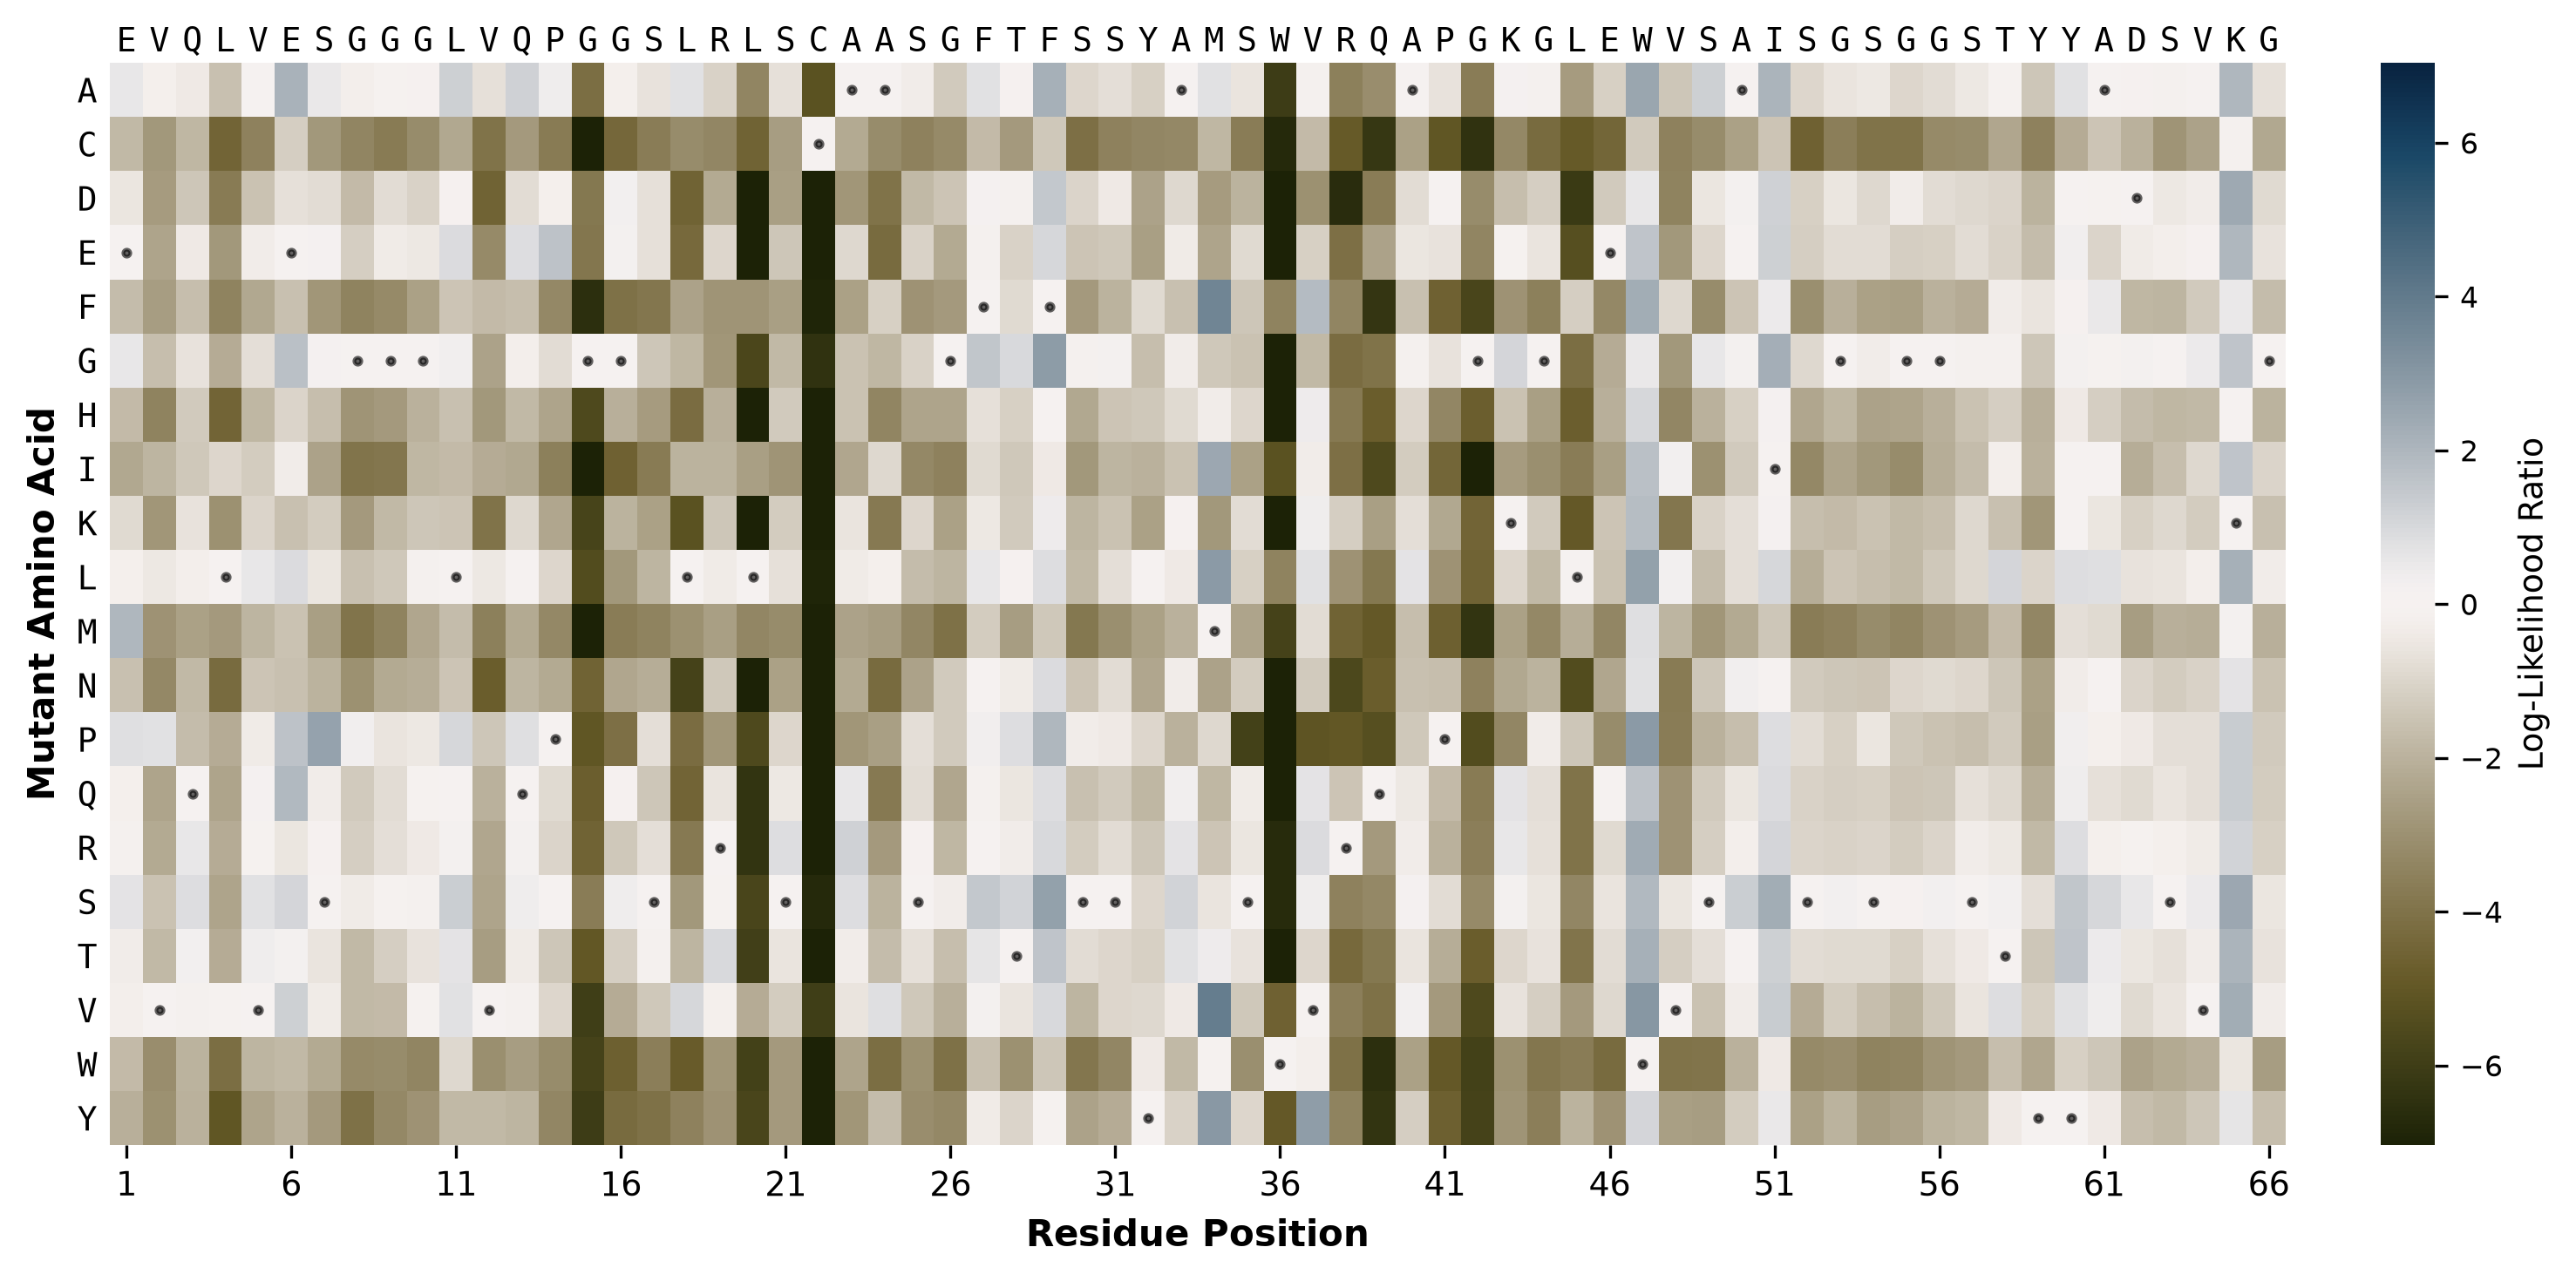

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as ticker
import numpy as np
import cmocean

def plot_mutation_heatmap_pub(scores, amino_acids, sequence,
                            start_pos=0, end_pos=None, ax=None):
    """
    Publication-ready mutation heatmap using cmocean.
    """
    if end_pos is None:
        end_pos = len(sequence)

    # 1. Data Subsetting
    scores_subset = scores[:, start_pos:end_pos]
    seq_subset = sequence[start_pos:end_pos]
    n_pos = len(seq_subset)
    n_aa = len(amino_acids)

    # 2. Setup Figure (allow passing an axis for subplotting)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6)) # Standard textbook aspect ratio

    # 3. Color Normalization (CRITICAL for difference maps)
    # This ensures 0 is always white, even if min is -6 and max is +2.
    # The saturation limit is pulled in by 3 LLR units for contrast, but that must
    # not be allowed to reach 0 or invert: TwoSlopeNorm requires
    # vmin < vcenter < vmax and raises ValueError otherwise, which is exactly what
    # a bare `vmax=max_abs-3` does whenever the scores span less than 3 units.
    max_abs = float(np.nanmax(np.abs(scores_subset)))
    lim = max_abs - 3 if max_abs > 3 else max_abs
    lim = max(lim, 1e-6)
    norm = colors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

    # 4. Plotting
    # Use cmocean.cm.diff_r (Blue=Beneficial, Brown=Deleterious usually)
    im = ax.imshow(scores_subset, aspect='auto', cmap=cmocean.cm.diff_r,
                   norm=norm, interpolation='nearest')

    # 5. Typographic & Tick Polish
    # Y-Axis: Monospace for alignment, lighter color for ticks
    ax.set_yticks(range(n_aa))
    ax.set_yticklabels(amino_acids, family='monospace', fontsize=9)
    ax.tick_params(axis='y', length=0) # Remove tick marks, keep labels

    # X-Axis: Logic to prevent overcrowding
    ax.set_xticks(range(n_pos))
    # Only label every 5th position if the sequence is long
    if n_pos > 20:
        major_locator = ticker.MultipleLocator(5)
        ax.xaxis.set_major_locator(major_locator)
        # Create labels based on the locator
        locs = ax.get_xticks()
        labels = [f"{start_pos + int(x) + 1}" for x in locs if x < n_pos]
        ax.set_xticklabels(labels, fontsize=9)
    else:
        # If short, show all numbers
        ax.set_xticklabels([str(start_pos + i + 1) for i in range(n_pos)], fontsize=9)

    ax.set_xlabel("Residue Position", fontsize=10, weight='bold')
    ax.set_ylabel("Mutant Amino Acid", fontsize=10, weight='bold')

    # 6. Mark Wild-Type (The "Textbook" way)
    # Instead of a box, we use a dot. It allows the color to be seen
    # and handles grayscale printing better than a black box border.
    wt_x = []
    wt_y = []
    for i, wt_aa in enumerate(seq_subset):
        if wt_aa in amino_acids:
            row_idx = amino_acids.index(wt_aa)
            wt_x.append(i)
            wt_y.append(row_idx)

    # Plot dots for WT
    ax.scatter(wt_x, wt_y, marker='.', s=15, c='black', alpha=0.6, label='Wild Type')

    # 7. Add Wild-Type Sequence on Top (Optional but helpful context)
    # Creates a secondary axis just to show the letters
    ax_top = ax.secondary_xaxis('top')
    ax_top.set_xticks(range(n_pos))
    ax_top.set_xticklabels(list(seq_subset), family='monospace', fontsize=9)
    ax_top.tick_params(axis='x', length=0, pad=1)
    ax_top.spines['top'].set_visible(False)

    # 8. Clean Spines
    for spine in ['top', 'right', 'bottom', 'left']:
        ax.spines[spine].set_visible(False)

    # 9. Professional Colorbar
    # Create a concise colorbar
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Log-Likelihood Ratio", fontsize=9)
    cbar.outline.set_visible(False) # Remove box around colorbar
    cbar.ax.tick_params(labelsize=8)

    return ax

# --- Usage ---
fig, ax = plt.subplots(figsize=(10, 5), dpi=300) # High DPI for print
plot_mutation_heatmap_pub(mutation_scores, amino_acids, wild_type_sequence, ax=ax)

plt.tight_layout()
plt.savefig("mutation_heatmap.png", dpi=300, bbox_inches='tight') # Saves the file
plt.savefig("mutation_heatmap.svg", bbox_inches='tight')
plt.show()

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Interactive Region Selector</h3>

For long sequences, we can interactively zoom into specific regions.

In [8]:
def create_interactive_heatmap(scores, amino_acids, sequence):
    """Create interactive widget to explore different regions."""

    # Create slider
    slider = widgets.IntRangeSlider(
        value=[0, min(50, len(sequence))],
        min=0,
        max=len(sequence),
        step=1,
        description='Region:',
        continuous_update=False,
        layout=widgets.Layout(width='600px')
    )

    def update_plot(change):
        start, end = slider.value
        print(f"\nDisplaying positions {start+1} to {end}")
        plot_mutation_heatmap(scores, amino_acids, sequence, start, end, figsize=(16, 8))

    slider.observe(update_plot, names='value')

    display(slider)
    # Initial plot
    update_plot(None)

# Uncomment to enable interactive mode
# create_interactive_heatmap(mutation_scores, amino_acids, wild_type_sequence)

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Identify Highly Conserved Positions</h3>

Positions where most mutations are deleterious are likely functionally critical.

In [9]:
def analyze_conservation(scores, sequence, amino_acids, threshold=-1.0):
    """
    Identify conserved positions based on mutation intolerance.

    Args:
        scores: LLR matrix
        sequence: Wild-type sequence
        amino_acids: List of amino acids
        threshold: LLR threshold for calling a mutation deleterious

    Returns:
        DataFrame with conservation analysis
    """
    results = []

    for pos in range(len(sequence)):
        wt_aa = sequence[pos]
        pos_scores = scores[:, pos]

        # Exclude wild-type from analysis
        wt_idx = amino_acids.index(wt_aa)
        mutation_scores = np.delete(pos_scores, wt_idx)

        # Statistics
        mean_score = mutation_scores.mean()
        min_score = mutation_scores.min()
        max_score = mutation_scores.max()
        deleterious_count = (mutation_scores < threshold).sum()
        beneficial_count = (mutation_scores > 0).sum()

        results.append({
            'Position': pos + 1,
            'Wild-Type': wt_aa,
            'Mean LLR': mean_score,
            'Min LLR': min_score,
            'Max LLR': max_score,
            'Deleterious (%)': 100 * deleterious_count / len(mutation_scores),
            'Beneficial (%)': 100 * beneficial_count / len(mutation_scores),
        })

    return pd.DataFrame(results)

# Analyze conservation
conservation_df = analyze_conservation(mutation_scores, wild_type_sequence, amino_acids)

# Display most conserved positions (highest % deleterious)
print("Most conserved positions (intolerant to mutations):")
print("=" * 70)
most_conserved = conservation_df.nlargest(10, 'Deleterious (%)')
print(most_conserved.to_string(index=False))

print("\n\nMost variable positions (tolerant to mutations):")
print("=" * 70)
most_variable = conservation_df.nsmallest(10, 'Deleterious (%)')
print(most_variable.to_string(index=False))

Most conserved positions (intolerant to mutations):
 Position Wild-Type  Mean LLR    Min LLR   Max LLR  Deleterious (%)  Beneficial (%)
       15         G -5.400749  -8.010595 -3.652619       100.000000             0.0
       20         L -5.505006  -8.636207 -2.185047       100.000000             0.0
       22         C -8.000498 -10.038059 -5.181168       100.000000             0.0
       36         W -6.718863  -9.665548 -3.424035       100.000000             0.0
       38         R -3.906610  -6.649855 -1.179213       100.000000             0.0
       39         Q -4.424620  -6.514092 -2.454135       100.000000             0.0
       42         G -4.778589  -7.117794 -3.158077       100.000000             0.0
       45         L -3.687991  -6.145540 -1.163333       100.000000             0.0
       26         G -2.278104  -4.032891 -0.323946        94.736842             0.0
        4         L -2.849194  -5.039100 -0.042072        89.473684             0.0


Most variable position

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§4&#8195;</span>Approach 2 - Deep Mutational Scanning (DMS)</h2>

In practice, we often have a **specific list of mutations** to evaluate (e.g., from experimental
screens or computational design). Instead of computing all possible mutations, we can score
just the variants we care about.

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Three Scoring Strategies</h3>

1. **Wild-Type Marginals** (`wt-marginals`): Single forward pass, fast but less accurate
2. **Masked Marginals** (`masked-marginals`): Mask each position, slower but **best performance**
3. **Pseudo-Perplexity** (`pseudo-ppl`): Evaluate entire mutated sequence

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Create Example Mutations</h3>

Let's create a list of mutations to score. Format: `{wt}{position}{mutant}`
Example: `A5G` means position 5, wild-type A, mutant G.

In [10]:
def parse_mutation(mutation: str) -> tuple[str, int, str]:
    """Split a mutation string like 'K43R' into (wild-type, 1-based position, mutant)."""
    return mutation[0], int(mutation[1:-1]), mutation[-1]


def apply_mutation(sequence: str, mutation: str) -> str:
    """
    Return `sequence` with `mutation` applied, validating the wild-type residue.

    Building mutant sequences through this helper (rather than by hand-slicing)
    keeps the mutation label and the sequence it produces from ever disagreeing.
    """
    wt, pos, mt = parse_mutation(mutation)
    if sequence[pos - 1] != wt:
        raise ValueError(
            f"{mutation}: expected wild-type {wt} at position {pos}, "
            f"but the sequence has {sequence[pos - 1]}"
        )
    return sequence[: pos - 1] + mt + sequence[pos:]


# Create example mutations. Each is chosen to illustrate a different substitution
# type, and every one is validated against wild_type_sequence by the assert below.
example_mutations = [
    "E1Q",   # Position  1: E → Q (conservative, both polar/charged)
    "E1W",   # Position  1: E → W (radical, charged to hydrophobic)
    "V5L",   # Position  5: V → L (conservative, both hydrophobic)
    "L4P",   # Position  4: L → P (proline, often disruptive)
    "S17A",  # Position 17: S → A (remove hydroxyl)
    "G15P",  # Position 15: G → P (glycine to proline, reduce flexibility)
    "A23G",  # Position 23: A → G (both small)
    "Y32F",  # Position 32: Y → F (remove hydroxyl from aromatic)
    "K43R",  # Position 43: K → R (both positive, conservative)
    "D62N",  # Position 62: D → N (negative to neutral)
]

print("Example mutations to score:")
for mut in example_mutations:
    wt, pos, mt = parse_mutation(mut)
    actual_wt = wild_type_sequence[pos-1]
    print(f"  {mut:8s} - Position {pos:2d}: {actual_wt} → {mt}")
    if wt != actual_wt:
        print(f"           WARNING: Expected {wt} but sequence has {actual_wt}")

# Guard: every example mutation must name the residue the sequence actually has.
# Mutations that fail validation are silently skipped by the scorer below, so
# without this assert a stale list quietly shrinks the results table instead of
# failing loudly.
mismatched = [m for m in example_mutations
              if wild_type_sequence[parse_mutation(m)[1] - 1] != parse_mutation(m)[0]]
assert not mismatched, f"Mutations do not match the wild-type sequence: {mismatched}"
print(f"\n✓ All {len(example_mutations)} mutations validated against the wild-type sequence.")

Example mutations to score:
  E1Q      - Position  1: E → Q
  E1W      - Position  1: E → W
  V5L      - Position  5: V → L
  L4P      - Position  4: L → P
  S17A     - Position 17: S → A
  G15P     - Position 15: G → P
  A23G     - Position 23: A → G
  Y32F     - Position 32: Y → F
  K43R     - Position 43: K → R
  D62N     - Position 62: D → N

✓ All 10 mutations validated against the wild-type sequence.


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Implementation: Masked Marginals Strategy</h3>

This is the **recommended** approach - mask each mutation position separately for accurate scoring.

In [11]:
def score_mutations_masked_marginals(mutations, sequence, model, tokenizer, device):
    """
    Score mutations using masked marginals strategy (recommended).

    For each mutation:
        1. Mask the mutation position
        2. Get model predictions
        3. Compute LLR = log P(mutant) - log P(wt)

    Args:
        mutations: List of mutation strings (e.g., ["A5G", "L10P"])
        sequence: Wild-type sequence
        model: ESM model
        tokenizer: ESM tokenizer
        device: torch device

    Returns:
        DataFrame with mutation scores
    """
    results = []

    model.eval()

    for mutation in tqdm(mutations, desc="Scoring mutations"):
        # Parse mutation
        wt_aa = mutation[0]
        pos = int(mutation[1:-1]) - 1  # Convert to 0-indexed
        mt_aa = mutation[-1]

        # Validate
        if sequence[pos] != wt_aa:
            print(f"Warning: {mutation} - expected {wt_aa} but found {sequence[pos]} at position {pos+1}")
            continue

        # Create masked sequence
        masked_seq = sequence[:pos] + tokenizer.mask_token + sequence[pos+1:]

        # Tokenize
        tokens = tokenizer(masked_seq, return_tensors="pt")
        tokens = {k: v.to(device) for k, v in tokens.items()}

        # Get predictions
        with torch.no_grad():
            outputs = model(**tokens)
            logits = outputs.logits

        # Find masked position
        mask_idx = (tokens['input_ids'] == tokenizer.mask_token_id).nonzero(as_tuple=True)[1][0]

        # Get log probabilities
        log_probs = F.log_softmax(logits[0, mask_idx], dim=0)

        # Get token IDs
        wt_token_id = tokenizer.convert_tokens_to_ids(wt_aa)
        mt_token_id = tokenizer.convert_tokens_to_ids(mt_aa)

        # Compute LLR
        wt_log_prob = log_probs[wt_token_id].item()
        mt_log_prob = log_probs[mt_token_id].item()
        llr = mt_log_prob - wt_log_prob

        # Store results
        results.append({
            'Mutation': mutation,
            'Position': pos + 1,
            'Wild-Type': wt_aa,
            'Mutant': mt_aa,
            'LLR': llr,
            'WT_LogProb': wt_log_prob,
            'MT_LogProb': mt_log_prob,
        })

    return pd.DataFrame(results)

# Score mutations
mutation_scores_df = score_mutations_masked_marginals(
    example_mutations,
    wild_type_sequence,
    model,
    tokenizer,
    device
)

print("\nMutation Scores (Masked Marginals Strategy):")
print("=" * 80)
print(mutation_scores_df.to_string(index=False))

Scoring mutations:   0%|          | 0/10 [00:00<?, ?it/s]


Mutation Scores (Masked Marginals Strategy):
Mutation  Position Wild-Type Mutant       LLR  WT_LogProb  MT_LogProb
     E1Q         1         E      Q -0.193385   -3.087284   -3.280670
     E1W         1         E      W -1.741720   -3.087284   -4.829004
     V5L         5         V      L  0.581820   -2.577764   -1.995943
     L4P         4         L      P -2.181258   -1.247972   -3.429230
    S17A        17         S      A -0.647699   -1.732581   -2.380279
    G15P        15         G      P -5.039169   -0.141083   -5.180252
    A23G        23         A      G -1.499415   -2.532142   -4.031557
    Y32F        32         Y      F -0.841774   -1.844641   -2.686415
    K43R        43         K      R  0.574528   -2.581919   -2.007390
    D62N        62         D      N -1.020758   -2.389929   -3.410687


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Interpret the Scores</h3>

In [12]:
def interpret_mutation_score(llr):
    """Provide human-readable interpretation of LLR score."""
    if llr < -2:
        return "Highly deleterious"
    elif llr < -1:
        return "Likely deleterious"
    elif llr < -0.5:
        return "Slightly deleterious"
    elif llr < 0.5:
        return "Neutral"
    elif llr < 1:
        return "Slightly beneficial"
    else:
        return "Likely beneficial"

# Add interpretation
mutation_scores_df['Interpretation'] = mutation_scores_df['LLR'].apply(interpret_mutation_score)

# Sort by score
mutation_scores_df_sorted = mutation_scores_df.sort_values('LLR')

print("\nMutations ranked by predicted effect:")
print("=" * 90)
print(mutation_scores_df_sorted[['Mutation', 'LLR', 'Interpretation']].to_string(index=False))


Mutations ranked by predicted effect:
Mutation       LLR       Interpretation
    G15P -5.039169   Highly deleterious
     L4P -2.181258   Highly deleterious
     E1W -1.741720   Likely deleterious
    A23G -1.499415   Likely deleterious
    D62N -1.020758   Likely deleterious
    Y32F -0.841774 Slightly deleterious
    S17A -0.647699 Slightly deleterious
     E1Q -0.193385              Neutral
    K43R  0.574528  Slightly beneficial
     V5L  0.581820  Slightly beneficial


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Visualize Mutation Scores</h3>

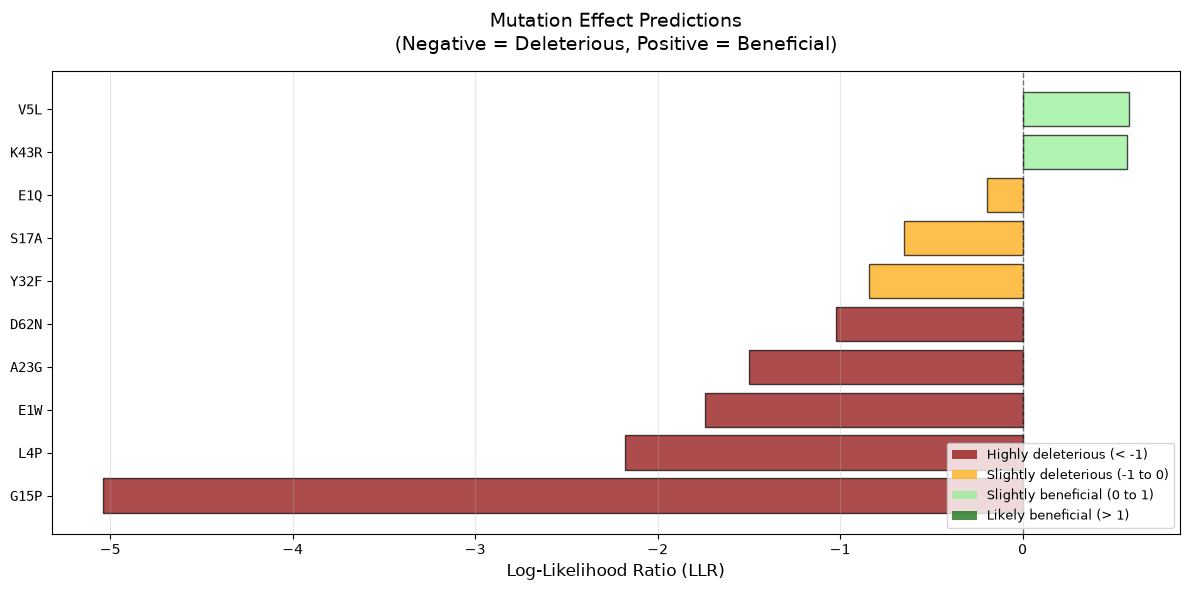

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))

# Sort by LLR for better visualization
sorted_df = mutation_scores_df.sort_values('LLR')

# Color bars by effect.
# NB: named `bar_colors`, not `colors` -- this cell used to rebind the global
# `colors`, which is `matplotlib.colors` (imported for plot_mutation_heatmap_pub
# above). Re-running the heatmap cell after this one then died with
# AttributeError: 'list' object has no attribute 'TwoSlopeNorm'.
bar_colors = ['darkred' if x < -1 else 'orange' if x < 0 else 'lightgreen' if x < 1 else 'darkgreen'
              for x in sorted_df['LLR']]

bars = ax.barh(range(len(sorted_df)), sorted_df['LLR'], color=bar_colors, alpha=0.7, edgecolor='black')

# Add mutation labels
ax.set_yticks(range(len(sorted_df)))
ax.set_yticklabels(sorted_df['Mutation'], fontsize=10, family='monospace')

# Add vertical line at 0
ax.axvline(x=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

# Labels and title
ax.set_xlabel('Log-Likelihood Ratio (LLR)', fontsize=12)
ax.set_title('Mutation Effect Predictions\n(Negative = Deleterious, Positive = Beneficial)',
             fontsize=14, pad=15)

# Add grid
ax.grid(axis='x', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='darkred', alpha=0.7, label='Highly deleterious (< -1)'),
    Patch(facecolor='orange', alpha=0.7, label='Slightly deleterious (-1 to 0)'),
    Patch(facecolor='lightgreen', alpha=0.7, label='Slightly beneficial (0 to 1)'),
    Patch(facecolor='darkgreen', alpha=0.7, label='Likely beneficial (> 1)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§5&#8195;</span>Approach 3 - Pseudo-Perplexity (PPPL)</h2>

Pseudo-perplexity evaluates the **overall quality** of an entire sequence, not just single mutations.
It's useful for:
- Comparing multiple sequence variants
- Evaluating designed sequences
- Quality control before experimental validation

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Algorithm</h3>

For each position i in the sequence:
1. Mask position i
2. Predict the probability of the actual amino acid
3. Take the log probability

PPPL = exp(-1/N × Σ log P(actual_aa_i | context))

**Lower PPPL = more natural sequence**

In [14]:
def compute_pseudo_perplexity(sequence, model, tokenizer, device):
    """
    Compute pseudo-perplexity for a protein sequence.

    Args:
        sequence: Protein sequence
        model: ESM model
        tokenizer: ESM tokenizer
        device: torch device

    Returns:
        pppl: Pseudo-perplexity score
        per_position_ll: Log-likelihood for each position
    """
    model.eval()

    n_positions = len(sequence)
    log_likelihoods = []

    for pos in range(n_positions):
        # Mask position
        masked_seq = sequence[:pos] + tokenizer.mask_token + sequence[pos+1:]

        # Tokenize
        tokens = tokenizer(masked_seq, return_tensors="pt")
        tokens = {k: v.to(device) for k, v in tokens.items()}

        # Get predictions
        with torch.no_grad():
            outputs = model(**tokens)
            logits = outputs.logits

        # Find masked position
        mask_idx = (tokens['input_ids'] == tokenizer.mask_token_id).nonzero(as_tuple=True)[1][0]

        # Get log probability of actual amino acid
        log_probs = F.log_softmax(logits[0, mask_idx], dim=0)
        actual_aa = sequence[pos]
        actual_token_id = tokenizer.convert_tokens_to_ids(actual_aa)
        log_likelihood = log_probs[actual_token_id].item()

        log_likelihoods.append(log_likelihood)

    # Compute pseudo-perplexity
    mean_ll = np.mean(log_likelihoods)
    pppl = np.exp(-mean_ll)

    return pppl, np.array(log_likelihoods)

# Compute PPPL for wild-type
print("Computing pseudo-perplexity for wild-type sequence...")
wt_pppl, wt_ll = compute_pseudo_perplexity(wild_type_sequence, model, tokenizer, device)

print(f"\nWild-type sequence:")
print(f"  Length: {len(wild_type_sequence)} aa")
print(f"  Pseudo-perplexity: {wt_pppl:.4f}")
print(f"  Mean log-likelihood: {wt_ll.mean():.4f}")
print(f"\nInterpretation:")
print(f"  Lower PPPL = more 'natural' sequence")
print(f"  Typical range: 1.5 - 20 (depends on protein family)")

Computing pseudo-perplexity for wild-type sequence...



Wild-type sequence:
  Length: 66 aa
  Pseudo-perplexity: 8.9383
  Mean log-likelihood: -2.1903

Interpretation:
  Lower PPPL = more 'natural' sequence
  Typical range: 1.5 - 20 (depends on protein family)


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Compare Multiple Sequences</h3>

Let's create a few mutant sequences and compare their PPPL scores.

In [15]:
# Create mutant sequences. `apply_mutation` validates the wild-type residue, so
# the label in the dict key and the sequence it describes cannot drift apart --
# the previous hand-sliced versions claimed "K46R"/"D50N" but position 46 is E and
# position 50 is A in this sequence, so they silently built E46R/A50N instead.
def apply_mutations(sequence: str, mutations: list[str]) -> str:
    """Apply several mutations to a sequence, validating each one."""
    for mutation in mutations:
        sequence = apply_mutation(sequence, mutation)
    return sequence


mutant_sequences = {
    'Wild-Type': wild_type_sequence,
    'Conservative (K43R)': apply_mutation(wild_type_sequence, 'K43R'),
    'Radical (E1W)': apply_mutation(wild_type_sequence, 'E1W'),
    'Multiple Mutations (K43R + D62N)': apply_mutations(wild_type_sequence, ['K43R', 'D62N']),
}

# Compute PPPL for each
pppl_results = []

for name, seq in mutant_sequences.items():
    print(f"\nScoring: {name}...")
    pppl, ll = compute_pseudo_perplexity(seq, model, tokenizer, device)
    pppl_results.append({
        'Variant': name,
        'PPPL': pppl,
        'Mean_LL': ll.mean(),
    })

pppl_df = pd.DataFrame(pppl_results)
pppl_df = pppl_df.sort_values('PPPL')

print("\n\nPseudo-perplexity Comparison:")
print("=" * 60)
print(pppl_df.to_string(index=False))
print("\nLower PPPL indicates more natural/stable sequence")


Scoring: Wild-Type...



Scoring: Conservative (K43R)...



Scoring: Radical (E1W)...



Scoring: Multiple Mutations (K43R + D62N)...




Pseudo-perplexity Comparison:
                         Variant     PPPL   Mean_LL
             Conservative (K43R) 8.838279 -2.179092
                       Wild-Type 8.938255 -2.190340
Multiple Mutations (K43R + D62N) 9.163475 -2.215225
                   Radical (E1W) 9.173848 -2.216357

Lower PPPL indicates more natural/stable sequence


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Visualize Per-Position Contributions</h3>

We can see which positions contribute most to the PPPL score.

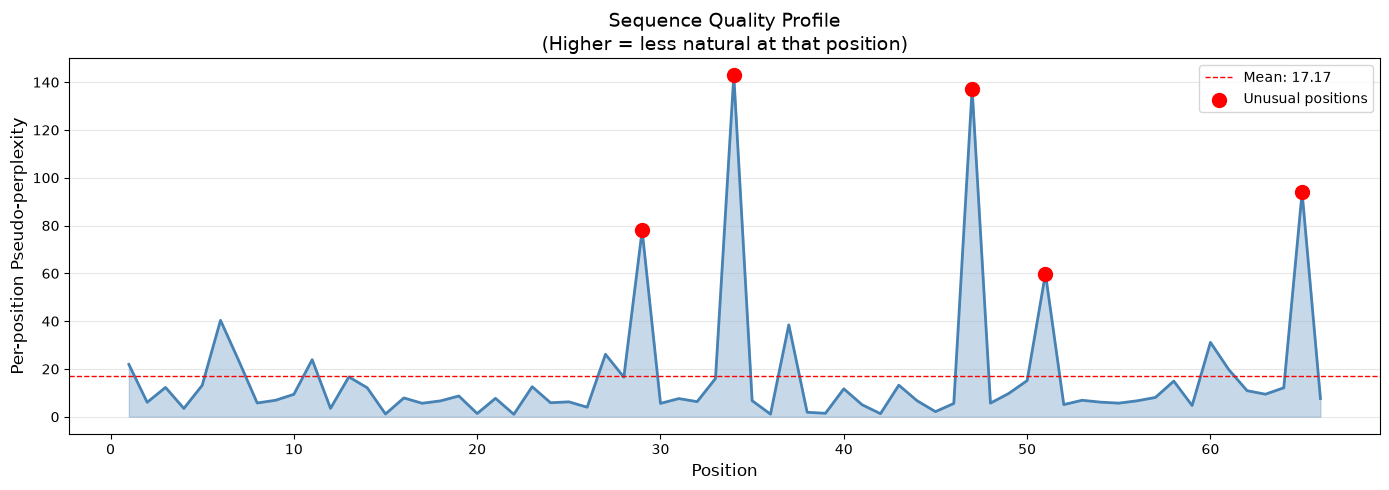


Positions with unusually high PPPL (potentially problematic):
  Position 29: F (PPPL = 77.97)
  Position 34: M (PPPL = 142.82)
  Position 47: W (PPPL = 137.29)
  Position 51: I (PPPL = 59.91)
  Position 65: K (PPPL = 93.94)


In [16]:
# Get per-position scores for wild-type
_, wt_per_pos = compute_pseudo_perplexity(wild_type_sequence, model, tokenizer, device)

# Plot
fig, ax = plt.subplots(figsize=(14, 5))

# Convert to per-position perplexity
per_pos_pppl = np.exp(-wt_per_pos)

positions = np.arange(1, len(wild_type_sequence) + 1)
ax.plot(positions, per_pos_pppl, linewidth=2, color='steelblue')
ax.fill_between(positions, per_pos_pppl, alpha=0.3, color='steelblue')

# Add horizontal line at mean
mean_pppl = per_pos_pppl.mean()
ax.axhline(y=mean_pppl, color='red', linestyle='--', linewidth=1, label=f'Mean: {mean_pppl:.2f}')

# Highlight high-scoring (problematic) positions
threshold = mean_pppl + per_pos_pppl.std()
problematic = per_pos_pppl > threshold
ax.scatter(positions[problematic], per_pos_pppl[problematic],
           color='red', s=100, zorder=5, label='Unusual positions')

ax.set_xlabel('Position', fontsize=12)
ax.set_ylabel('Per-position Pseudo-perplexity', fontsize=12)
ax.set_title('Sequence Quality Profile\n(Higher = less natural at that position)', fontsize=14)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nPositions with unusually high PPPL (potentially problematic):")
for pos in positions[problematic]:
    aa = wild_type_sequence[pos-1]
    score = per_pos_pppl[pos-1]
    print(f"  Position {pos}: {aa} (PPPL = {score:.2f})")

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§6&#8195;</span>Practical Application - Antibody Optimization</h2>

Let's apply these methods to a real-world scenario: improving an antibody's properties while
maintaining binding specificity.

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Scenario</h3>
We have an antibody that binds our target but has:
- Suboptimal stability
- Potential immunogenic hotspots

Goal: Identify mutations that:
1. Don't disrupt conserved binding residues (CDRs)
2. Improve overall sequence quality
3. Remove unusual/immunogenic patterns

In [17]:
# Identify framework vs CDR regions (simplified annotation)
# In real antibodies, CDRs are positions ~26-33, 51-57, 96-102 (Kabat numbering)
# For our sequence, let's mark some regions as "critical" (CDR-like).
# NOTE: these are 0-INDEXED offsets into wild_type_sequence (they are compared
# against a 0-indexed `pos` below), so they cover the 1-indexed residues 15-22
# and 41-48 that the report's "Position" column reports.
critical_positions = list(range(14, 22)) + list(range(40, 48))  # Example CDR positions

print("Critical positions (conserved, binding-related):")
print(f"  0-indexed : {critical_positions}")
print(f"  1-indexed : {[i + 1 for i in critical_positions]}")
print(f"  Residues  : {''.join(wild_type_sequence[i] for i in critical_positions)}")

Critical positions (conserved, binding-related):
  0-indexed : [14, 15, 16, 17, 18, 19, 20, 21, 40, 41, 42, 43, 44, 45, 46, 47]
  1-indexed : [15, 16, 17, 18, 19, 20, 21, 22, 41, 42, 43, 44, 45, 46, 47, 48]
  Residues  : GGSLRLSCPGKGLEWV


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Strategy: Find Stabilizing Mutations Outside CDRs</h3>

In [18]:
# Find positions outside CDRs that tolerate beneficial mutations
optimization_candidates = []

for pos in range(len(wild_type_sequence)):
    if pos in critical_positions:
        continue  # Skip critical positions

    wt_aa = wild_type_sequence[pos]
    pos_scores = mutation_scores[:, pos]

    # Find amino acids with positive LLR (potentially beneficial)
    for aa_idx, aa in enumerate(amino_acids):
        if aa == wt_aa:
            continue

        llr = pos_scores[aa_idx]
        if llr > 0.5:  # Threshold for "beneficial"
            optimization_candidates.append({
                'Position': pos + 1,
                'Wild-Type': wt_aa,
                'Mutant': aa,
                'LLR': llr,
                'Mutation': f"{wt_aa}{pos+1}{aa}"
            })

# Sort by LLR
optimization_df = pd.DataFrame(optimization_candidates)
optimization_df = optimization_df.sort_values('LLR', ascending=False).head(15)

print("\nTop 15 optimization candidates (outside critical regions):")
print("=" * 70)
print(optimization_df.to_string(index=False))


Top 15 optimization candidates (outside critical regions):
 Position Wild-Type Mutant      LLR Mutation
       34         M      V 3.898731     M34V
       34         M      F 3.603187     M34F
       34         M      Y 2.935418     M34Y
       34         M      L 2.876055     M34L
       29         F      G 2.846795     F29G
       37         V      Y 2.770151     V37Y
       29         F      S 2.682701     F29S
        7         S      P 2.585355      S7P
       34         M      I 2.473510     M34I
       65         K      S 2.425039     K65S
       65         K      D 2.391594     K65D
       65         K      V 2.290742     K65V
       51         I      S 2.258465     I51S
       51         I      G 2.218907     I51G
       65         K      L 2.170877     K65L


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Evaluate Combined Mutations</h3>

Let's create a sequence with multiple beneficial mutations and check its PPPL.

In [19]:
# Select top 3 non-overlapping mutations
top_mutations = optimization_df.head(3)

# Create optimized sequence
optimized_sequence = list(wild_type_sequence)
for _, row in top_mutations.iterrows():
    pos = row['Position'] - 1
    mt = row['Mutant']
    optimized_sequence[pos] = mt

optimized_sequence = ''.join(optimized_sequence)

print("Optimized sequence (with 3 mutations):")
print(f"  Mutations: {', '.join(top_mutations['Mutation'].tolist())}")

# Compare PPPL
wt_pppl_final, _ = compute_pseudo_perplexity(wild_type_sequence, model, tokenizer, device)
opt_pppl, _ = compute_pseudo_perplexity(optimized_sequence, model, tokenizer, device)

print(f"\nPseudo-perplexity comparison:")
print(f"  Wild-type:  {wt_pppl_final:.4f}")
print(f"  Optimized:  {opt_pppl:.4f}")
print(f"  Change:     {opt_pppl - wt_pppl_final:+.4f}")

if opt_pppl < wt_pppl_final:
    print(f"\n✓ Optimized sequence is MORE natural (lower PPPL)")
else:
    print(f"\n✗ Optimized sequence is LESS natural (higher PPPL)")

Optimized sequence (with 3 mutations):
  Mutations: M34V, M34F, M34Y



Pseudo-perplexity comparison:
  Wild-type:  8.9383
  Optimized:  8.8679
  Change:     -0.0704

✓ Optimized sequence is MORE natural (lower PPPL)


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§7&#8195;</span>Model Size Comparison</h2>

Different ESM-2 model sizes offer trade-offs between speed and accuracy. Let's demonstrate
how to quickly switch models.

In [20]:
def compare_model_sizes(sequence, mutation, model_names):
    """
    Score a single mutation using different model sizes.

    Args:
        sequence: Wild-type sequence
        mutation: Mutation string (e.g., "A5G")
        model_names: List of model names to compare

    Returns:
        DataFrame with comparison results
    """
    results = []

    # Parse mutation
    wt_aa = mutation[0]
    pos = int(mutation[1:-1]) - 1
    mt_aa = mutation[-1]

    for model_name in model_names:
        print(f"Loading {model_name}...")

        # Load model
        tok = AutoTokenizer.from_pretrained(model_name)
        mdl = EsmForMaskedLM.from_pretrained(model_name)
        mdl = mdl.to(device)
        mdl.eval()

        # Time the scoring
        import time
        start = time.time()

        # Mask and score
        masked_seq = sequence[:pos] + tok.mask_token + sequence[pos+1:]
        tokens = tok(masked_seq, return_tensors="pt")
        tokens = {k: v.to(device) for k, v in tokens.items()}

        with torch.no_grad():
            outputs = mdl(**tokens)

        mask_idx = (tokens['input_ids'] == tok.mask_token_id).nonzero(as_tuple=True)[1][0]
        log_probs = F.log_softmax(outputs.logits[0, mask_idx], dim=0)

        wt_token_id = tok.convert_tokens_to_ids(wt_aa)
        mt_token_id = tok.convert_tokens_to_ids(mt_aa)

        llr = log_probs[mt_token_id].item() - log_probs[wt_token_id].item()

        elapsed = time.time() - start

        results.append({
            'Model': model_name.split('/')[-1],
            'Parameters': sum(p.numel() for p in mdl.parameters()),
            'LLR': llr,
            'Time (s)': elapsed,
        })

        # Clean up
        del mdl, tok
        torch.cuda.empty_cache()

    return pd.DataFrame(results)

# Compare models (only if you have enough memory)
print("\nComparing ESM-2 model sizes...")
print("(This may take a few minutes and requires significant GPU memory)")

# Uncomment to run comparison (requires sufficient GPU memory)
# model_comparison = compare_model_sizes(
#     wild_type_sequence,
#     "E1W",
#     ["facebook/esm2_t6_8M_UR50D",
#      "facebook/esm2_t12_35M_UR50D",
#      "facebook/esm2_t30_150M_UR50D"]
# )
# print("\n", model_comparison.to_string(index=False))


Comparing ESM-2 model sizes...
(This may take a few minutes and requires significant GPU memory)


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§8&#8195;</span>Export Results for Experimental Validation</h2>

Let's create a comprehensive report that experimentalists can use to prioritize mutations.

In [21]:
# Create comprehensive report
report = []

for pos in range(len(wild_type_sequence)):
    wt_aa = wild_type_sequence[pos]
    is_critical = pos in critical_positions

    # Get top 3 best and worst mutations
    pos_scores = mutation_scores[:, pos]

    for aa_idx, aa in enumerate(amino_acids):
        if aa == wt_aa:
            continue

        llr = pos_scores[aa_idx]

        report.append({
            'Mutation': f"{wt_aa}{pos+1}{aa}",
            'Position': pos + 1,
            'WT': wt_aa,
            'MT': aa,
            'LLR': llr,
            'Effect': interpret_mutation_score(llr),
            'Critical_Region': 'Yes' if is_critical else 'No',
            'Priority': 'High' if not is_critical and llr > 0.5 else 'Low'
        })

report_df = pd.DataFrame(report)

# Save to CSV
report_df.to_csv('mutation_report.csv', index=False)
print("Full report saved to: mutation_report.csv")

# Show summary
print("\nSummary statistics:")
print(f"  Total mutations evaluated: {len(report_df)}")
print(f"  Predicted deleterious: {(report_df['LLR'] < -1).sum()}")
print(f"  Predicted neutral: {((report_df['LLR'] >= -1) & (report_df['LLR'] < 1)).sum()}")
print(f"  Predicted beneficial: {(report_df['LLR'] >= 1).sum()}")
print(f"\n  High priority candidates (beneficial, non-critical): {(report_df['Priority'] == 'High').sum()}")

# Show top recommendations
print("\nTop 10 recommended mutations for experimental testing:")
print("=" * 90)
recommendations = report_df[report_df['Priority'] == 'High'].nlargest(10, 'LLR')
print(recommendations[['Mutation', 'LLR', 'Effect', 'Critical_Region']].to_string(index=False))

Full report saved to: mutation_report.csv

Summary statistics:
  Total mutations evaluated: 1254
  Predicted deleterious: 767
  Predicted neutral: 416
  Predicted beneficial: 71

  High priority candidates (beneficial, non-critical): 110

Top 10 recommended mutations for experimental testing:
Mutation      LLR            Effect Critical_Region
    M34V 3.898731 Likely beneficial              No
    M34F 3.603187 Likely beneficial              No
    M34Y 2.935418 Likely beneficial              No
    M34L 2.876055 Likely beneficial              No
    F29G 2.846795 Likely beneficial              No
    V37Y 2.770151 Likely beneficial              No
    F29S 2.682701 Likely beneficial              No
     S7P 2.585355 Likely beneficial              No
    M34I 2.473510 Likely beneficial              No
    K65S 2.425039 Likely beneficial              No


<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">Summary</h2>

 Mutation effect prediction with ESM-2 leverages evolutionary patterns learned from millions of sequences to score variants computationally. Log-likelihood ratios quantify whether mutations increase or decrease sequence plausibility. Comprehensive mutation landscapes reveal conserved and variable regions, guiding where mutations are tolerable. Targeted scoring of specific mutations enables efficient evaluation of design candidates or disease variants. Pseudo-perplexity assesses overall sequence quality, catching problematic combinations. Together, these approaches transform protein engineering workflows from exhaustive experimental screening to hypothesis-driven testing of computationally prioritized variants.

 While genomic sequencing has identified hundreds of millions of protein sequences, experimental methods like X-ray crystallography have determined the 3D structures for only a tiny fraction of them. This disconnect creates a massive "blind spot" in drug discovery, as knowing the 3D structure is critical. Deep learning bridges this gap by computationally predicting structures for the millions of sequences that lack experimental data.

 Proteins are not static strings; they are dynamic chains that fold into precise hierarchies – from local helices and sheets to global 3D arrangements. This folding is driven by physical forces, such as the "hydrophobic effect," where oily parts of the protein collapse inward to escape water. A successful prediction model must implicitly learn these geometric constraints and physical laws to distinguish valid biological shapes from random tangles.

 SimpleFold approaches structure prediction not just as a regression problem, but as a generative one using "flow matching." Similar to how AI might generate art, the model learns to guide a cloud of random noise into a structured protein shape over several steps. This allows the model to capture the complex distribution of possible protein conformations rather than just predicting a single average structure.

 Proteins have complex long-range dependencies; an AA at the beginning of a chain might chemically interact with one at the very end. Traditional sequential models (like RNNs) struggle to "remember" these distant connections due to information bottlenecks. Transformers solve this using self-attention, which allows every part of the sequence to look at and influence every other part simultaneously, regardless of how far apart they are.

 By training models on millions of raw protein sequences using "Masked Language Modeling", hiding parts of a sequence and asking the model to fill in the blanks, we force the model to learn fundamental rules of biology. The model learns which AA patterns are evolutionarily conserved and structurally stable without needing explicit labels, creating rich representations of proteins.

 The "knowledge" a model gains during pre-training can be transferred to specific drug discovery tasks. We demonstrated this by adapting a protein language model to classify antibodies, distinguishing between those that target HIV-1 and SARS-CoV-2. This highlights how a general understanding of protein language can be fine-tuned to solve highly specific biological classification problems with limited labeled data.

 Advanced models like ESM-2 are so capable that they can predict the effects of mutations without further training, a technique called "zero-shot" inference. By scoring how "natural" a mutated sequence looks to the model, researchers can identify stabilizing mutations or flag deleterious ones. This enables computational screening of thousands of therapeutic candidates before a single experiment is run in the lab.

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">Conclusion</h2>

You've now learned how to use ESM-2 for comprehensive mutation effect prediction!

**What you can do**:
- Create mutation heatmaps showing effects across entire sequences
- Score specific mutations with three different strategies
- Evaluate sequence quality with pseudo-perplexity
- Optimize proteins for stability and function
- Prioritize mutations for experimental validation

**Remember**: These are predictions based on evolutionary patterns. Always validate
critical mutations experimentally. But as a screening and prioritization tool,
ESM-2 can dramatically reduce the experimental search space!